# 실습 5 – Transformer

## 실습 개념 흐름

- N-gram
- Word2Vec
- Vanilla RNN
- LSTM
- Single-head Self-Attention
- Basic Transformer
- Hugging Face / Modern LLM

## Vanilla Attention

- Single-head causal self-attention 모델부터 시작한다.
  - 순차적인 메모리를 사용하는 대신 이전 단어들을 직접 살펴본다.

$$
Q=XW_Q,\quad K=XW_K,\quad V=XW_V,\quad
Attention(Q,K,V)=softmax\left(\frac{QK^T}{\sqrt{d}}\right)
$$

- Self-attention에서의 causal mask
  - **Keys**: Attention을 수행할 수 있는 위치
  - **Query**: 현재 토큰
  - ✓: Attention 가능(허용)
  - ✗: Attention 불가능(masked)
  - **예시: `"chinese"` 예측** — 모델이 `"chinese"` 토큰에 있을 때 `<BOS>`, `i`, `want`, `chinese`에는 Attention을 수행할 수 있다. 미래 토큰인 `"food"`는 볼 수 없다.
  - 미래 위치를 0으로 만드는 이 상삼각 마스크를 **causal mask**라고 한다. 이 마스크는 모델이 다음 토큰을 예측할 때 과거 정보만 사용하도록 보장한다.

<p align="center"><img src="images/img-2026-10-28-11-16-34.png" width="60%"/></p>


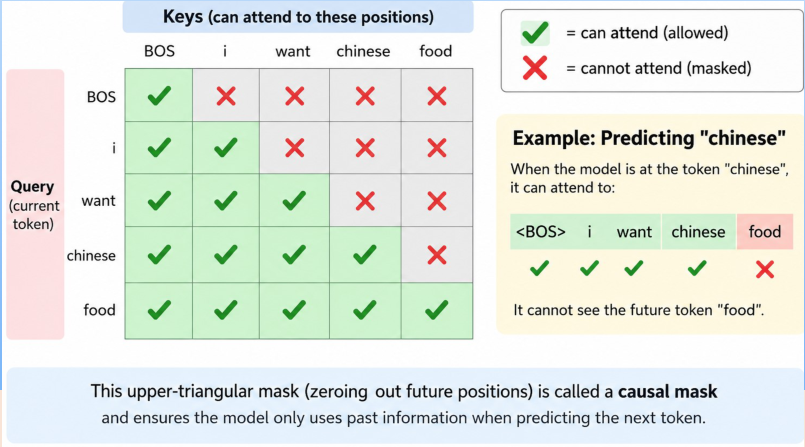

## Vanilla Attention

```python
class AttentionLanguageModel(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=64,
        max_len=MAX_LEN
        ):
        
        super().__init__()

        self.embedding_dim = embedding_dim

        self.token_embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=cm.PAD_ID
        )

        self.position_embedding = nn.Embedding(
            max_len,
            embedding_dim
        )
```

### 토큰 임베딩과 위치 임베딩

**코드**

```python
batch_size, seq_len = x.shape

positions = torch.arange(seq_len, dtype=torch.long, device=x.device)

h = {
    self.token_embedding(x) + self.position_embedding(positions)
}
```

**코드의 동작**

1. `batch_size, seq_len = x.shape`: 입력으로부터 배치 크기와 시퀀스 길이를 가져온다.
2. `positions = torch.arange(seq_len, ...)`: 위치 인덱스 `[0, 1, 2, ..., seq_len-1]`를 생성한다.
3. `positions = positions.unsqueeze(0)`: 배치 차원을 추가한다. Shape은 `[1, seq_len]`이 된다.
4. `self.token_embedding(x)`: 토큰 ID를 토큰 임베딩으로 변환한다. Shape은 `[batch_size, seq_len, d_model]`이다.
5. `self.position_embedding(positions)`: 위치 인덱스를 위치 임베딩으로 변환한다. Shape은 `[1, seq_len, d_model]`이며 배치에 broadcasting된다.
6. **두 임베딩을 더한다.** 원소별 덧셈으로 최종 입력 `h`를 얻으며 Shape은 `[batch_size, seq_len, d_model]`이다.

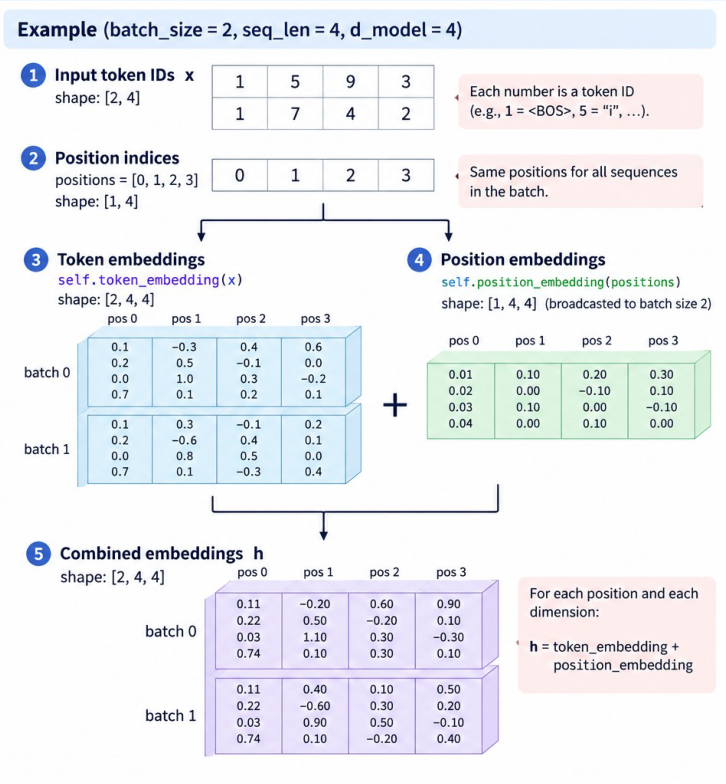

**예시 (`batch_size = 2, seq_len = 4, d_model = 4`)**

1. 입력 토큰 ID `x`: Shape `[2, 4]`. 각 숫자는 토큰 ID이다(예: `1 = <BOS>`, `5 = "i"`).
2. 위치 인덱스 `positions = [0, 1, 2, 3]`: Shape `[1, 4]`. 배치 내 모든 시퀀스가 동일한 위치를 사용한다.
3. 토큰 임베딩: `self.token_embedding(x)`, Shape `[2, 4, 4]`.
4. 위치 임베딩: `self.position_embedding(positions)`, Shape `[1, 4, 4]`(배치 크기 2로 broadcasting).
5. 결합된 임베딩 `h`: Shape `[2, 4, 4]`. 각 위치와 각 차원에서 `h = token_embedding + position_embedding`.

```python
self.query = nn.Linear(
    embedding_dim,
    embedding_dim,
    bias=False
)
self.key = nn.Linear(
    embedding_dim,
    embedding_dim,
    bias=False
)
self.value = nn.Linear(
    embedding_dim,
    embedding_dim,
    bias=False
)
self.output = nn.Linear(
    embedding_dim,
    vocab_size
)
```

`class torch.nn.Linear(in_features, out_features, bias=True, device=None, dtype=None)`

입력 데이터에 affine linear transformation을 적용한다. : &y=xA^T+b&

`torch.nn.Linear`에서 weight tensor는 `(out_features, in_features)` Shape으로 저장된다.

### `unsqueeze`와 행렬 곱셈

```python
def forward(self, x):
    batch_size, seq_len = x.shape
    positions = torch.arange(
        seq_len,
        device=x.device
    )

    positions = positions.unsqueeze(0)

    h = (
        self.token_embedding(x) +
        self.position_embedding(positions)
    )
    Q = self.query(h)
    K = self.key(h)
    V = self.value(h)

    scores = torch.matmul(
        Q,
        K.transpose(-2, -1)
    )
    
    scores = scores/math.sqrt(
        self.embedding_dim
    )
```

`unsqueeze(0)`은 배치 차원을 추가할 때 사용한다. Tensor의 Shape을 1D `(seq_len,)`에서 2D `(1, seq_len)`으로 바꿔 배치 간 broadcasting이 가능하도록 한다.


다음 예시에서:

```python
A = torch.tensor([[1, 2, 3], [4, 5, 6]])
B = torch.tensor([[7, 8], [9, 1], [2, 3]])
C = torch.matmul(A, B)
```

$$
C[(0,0)]=1\times7+2\times9+3\times2=7+18+6=31
$$

`K.transpose(-2, -1)`은 Tensor `K`의 마지막 두 차원을 서로 바꾼다.

### Causal masking

```python
# Causal Masking
causal_mask = torch.triu(
    torch.ones(
        seq_len,
        seq_len,
        device=x.device,
        dtype=torch.bool
    ),
    diagonal=1
)

scores = scores.masked_fill(
    causal_mask,
    float("-inf")
)
```

- `torch.ones(seq_len, seq_len, device=x.device, dtype=torch.bool)`: 입력 Tensor `x`와 동일한 장치(CPU/GPU)에, 값이 `True`로 채워진 `(seq_len, seq_len)` Shape의 정사각 Boolean 행렬을 생성한다.
- `torch.triu(..., diagonal=1)`: 행렬의 상삼각 부분을 추출하고 나머지 원소는 0으로 남긴다.

<p align="center"><img src="images/img-2026-10-28-11-32-11.png" width="50%"/></p>

- `masked_fill(causal_mask, float("-inf"))`: Boolean `causal_mask`를 확인하여 Mask가 `True`인 곳의 `scores` 행렬 값을 음의 무한대(`float("-inf")`)로 바꾼다.

### Padding mask

```python
padding_mask = (x==cm.PAD_ID
).unsqueeze(1)

scores = scores.masked_fill(
    padding_mask,
    float("-inf")
)

attention_weights = F.softmax(
    scores,
    dim=-1
)

context = torch.matmul(
    attention_weights,
    V
)

logits = self.output(context)

return logits
```

- `x == cm.PAD_ID`: 비교 연산을 통해 같은 Shape `(batch_size, seq_len)`의 Boolean Tensor를 생성한다.
- `.unsqueeze(1)`: 인덱스 1에 새로운 차원을 삽입한다. `padding_mask`의 Shape이 `(batch_size, seq_len)`에서 `(batch_size, 1, seq_len)`으로 바뀐다.

### Train & Text Generation

```python
attention_model = AttentionLanguageModel(
    vocab_size=cm.vocab_size
).to(cm.device)

cm.train_model(
    attention_model,
    cm.loader,
    epochs=250,
)

prompts = [
    "i want",
    "find a",
    "show me",
    "can you",
    "where can"
]

for prompt in prompts:
    print(
        prompt,
        "→",
        cm.generate_text(
            attention_model,
            prompt=prompt
        )
    )
```

In [ ]:
class AttentionLanguageModel(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=64,
        max_len=MAX_LEN
    ):
        super().__init__()

        self.embedding_dim = embedding_dim
        self.token_embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=cm.PAD_ID
        )
        self.position_embedding = nn.Embedding(
            max_len,
            embedding_dim
        )

        # 6쪽: Linear는 y = xA^T + b의 affine linear transformation을 적용한다.
        # weight의 Shape: (out_features, in_features)
        self.query = nn.Linear(
            embedding_dim,
            embedding_dim,
            bias=False
        )
        self.key = nn.Linear(
            embedding_dim,
            embedding_dim,
            bias=False
        )
        self.value = nn.Linear(
            embedding_dim,
            embedding_dim,
            bias=False
        )
        self.output = nn.Linear(
            embedding_dim,
            vocab_size
        )

    def forward(self, x):
        batch_size, seq_len = x.shape

        positions = torch.arange(
            seq_len,
            device=x.device
        )
        # 7쪽: 배치 차원을 추가한다. (seq_len,) -> (1, seq_len)
        # 배치 간 broadcasting에 사용한다.
        positions = positions.unsqueeze(0)
        h = (
            self.token_embedding(x) +
            self.position_embedding(positions)
        )

        Q = self.query(h)
        K = self.key(h)
        V = self.value(h)

        # 7쪽: torch.matmul은 행렬 곱셈을 수행한다.
        # A=[[1,2,3],[4,5,6]], B=[[7,8],[9,1],[2,3]]일 때
        # C[(0,0)] = 1*7 + 2*9 + 3*2 = 31
        # K.transpose(-2, -1)은 K의 마지막 두 차원을 교환한다.
        scores = torch.matmul(
            Q,
            K.transpose(-2, -1)
        )
        scores = scores/math.sqrt(
            self.embedding_dim
        )

        # Causal Masking
        # 8쪽: torch.ones는 입력과 같은 장치에 True로 채운 정사각 Boolean 행렬을 생성한다.
        # triu(..., diagonal=1)은 상삼각 부분만 남기고 나머지를 0으로 둔다.
        causal_mask = torch.triu(
            torch.ones(
                seq_len,
                seq_len,
                device=x.device,
                dtype=torch.bool
            ),
            diagonal=1
        )
        # Mask가 True인 scores 값을 음의 무한대(-inf)로 바꾼다.
        scores = scores.masked_fill(
            causal_mask,
            float("-inf")
        )

        # 9쪽: x == cm.PAD_ID는 (batch_size, seq_len) Shape의 Boolean Tensor를 만든다.
        # unsqueeze(1)은 인덱스 1에 새 차원을 넣는다.
        # (batch_size, seq_len) -> (batch_size, 1, seq_len)
        padding_mask = (x==cm.PAD_ID).unsqueeze(1)
        scores = scores.masked_fill(
            padding_mask,
            float("-inf")
        )
        attention_weights = F.softmax(
            scores,
            dim=-1
        )
        context = torch.matmul(
            attention_weights,
            V
        )
        logits = self.output(context)

        return logits

## 10쪽 · Vanilla Attention: 학습 및 텍스트 생성

In [ ]:
attention_model = AttentionLanguageModel(
    vocab_size=cm.vocab_size
).to(cm.device)

cm.train_model(
    attention_model,
    cm.loader,
    epochs=250,
)

prompts = [
    "i want",
    "find a",
    "show me",
    "can you",
    "where can"
]

for prompt in prompts:
    print(
        prompt,
        "→",
        cm.generate_text(
            attention_model,
            prompt=prompt
        )
    )

## Attention에서 Causal Mask + Padding Mask

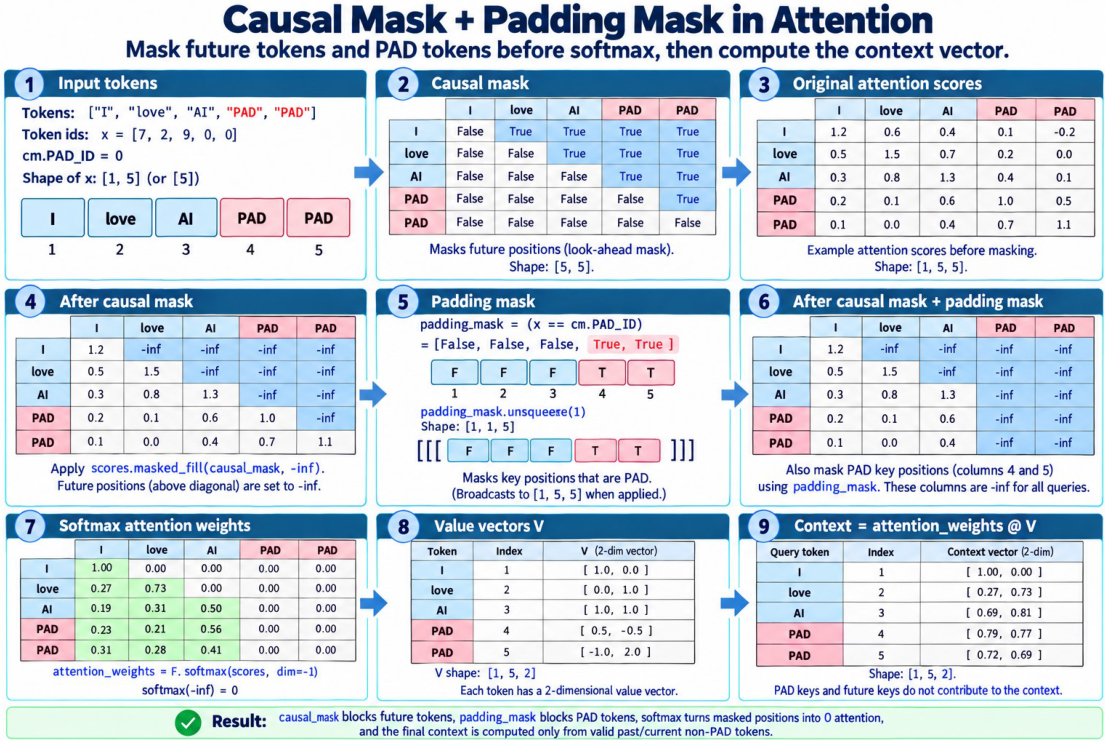

## 12–15쪽 · Basic Transformer

### 12쪽 · Multi-head self-attention

- `num_heads` (**Number of Attention Heads**): Attention 메커니즘을 여러 개의 독립적인 "head"로 분할한다. 이를 통해 모델은 서로 다른 종류의 관계를 동시에 살펴볼 수 있다(예: 한 head는 문법을 추적하고, 다른 head는 대명사의 지시 대상을 추적한다).
- `ff_dim` (**Feed-Forward Dimension**): Transformer block 내부의 위치별 feed-forward network(FFN)의 hidden layer 크기이다. Attention layer에서 추출한 특징을 바탕으로 복잡한 비선형 패턴을 학습할 수 있도록 모델에 추가적인 용량을 제공한다.

### 13쪽 · Feed-forward network 및 정규화

- `nn.Sequential(layers)`: 나열한 순서 그대로 Layer를 차례대로 자동 실행한다. 한 Layer의 출력이 다음 Layer의 입력으로 직접 전달된다.
- `forward` 메서드에서 각각의 Layer에 입력을 직접 전달할 필요를 없애 코드를 단순화한다.

\[
W_2 	imes ReLU(W_1 	imes output_i + b_i)+b_2
\]

- `LayerNorm`: 특징 차원(feature dimensions)에 걸쳐 평균과 표준편차를 계산하고 값을 표준화한다(평균을 0으로, 분산을 1로 맞춘다).

### 14쪽 · Mask

- Attention을 수행하지 않아야 하는 모든 위치를 `True`로 masking한다.

### 15쪽 · Multi-head attention

- `h, h, h` (**Query, Key, Value**): Self-attention에서는 세 입력 모두 동일한 Tensor `h`이다.
- `attn_mask`: 상삼각 mask이다.
- `key_padding_mask`: Attention 메커니즘이 padding token을 무시하도록 지정한다.
- `need_weights`: Attention 행렬을 반환한다.

In [ ]:
class TransformerLanguageModel(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=64,
        num_heads=4,
        ff_dim=128,
        max_len=MAX_LEN
    ):
        super().__init__()
        self.token_embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_ID
        )
        self.position_embedding = nn.Embedding(
            max_len,
            embedding_dim
        )

        # Multi-head self-attention
        # num_heads: 서로 다른 관계를 동시에 살펴보는 독립적인 Attention head의 수.
        self.attention = nn.MultiheadAttention(
            embed_dim=embedding_dim,
            num_heads=num_heads,
            batch_first=True
        )

        # Feed-forward network
        # 13쪽: Sequential은 나열한 Layer들을 차례로 실행하고
        # 앞 Layer의 출력을 다음 Layer의 입력으로 전달한다.
        # ff_dim: FFN 내부 hidden layer의 크기.
        # W2 x ReLU(W1 x output_i + b_i) + b2
        self.ffn = nn.Sequential(
            nn.Linear(
                embedding_dim,
                ff_dim
            ),
            nn.ReLU(),
            nn.Linear(
                ff_dim,
                embedding_dim
            )
        )

        # LayerNorm은 특징 차원의 평균과 표준편차를 계산하여
        # 평균 0, 분산 1로 값을 표준화한다.
        self.norm1 = nn.LayerNorm(embedding_dim)
        self.norm2 = nn.LayerNorm(embedding_dim)
        self.output = nn.Linear(
            embedding_dim,
            vocab_size
        )

    def forward(self, x):
        batch_size, seq_len = x.shape

        # Embeddings
        positions = torch.arange(
            seq_len,
            device=x.device
        ).unsqueeze(0)
        h = (
            self.token_embedding(x)
            + self.position_embedding(positions)
        )

        # 14쪽: Attention하지 않을 모든 위치를 True로 masking한다.
        causal_mask = torch.triu(
            torch.ones(
                seq_len,
                seq_len,
                device=x.device,
                dtype=torch.bool
            ),
            diagonal=1
        )
        padding_mask = (x == PAD_ID)

        # Multi-head attention
        # 15쪽: Q, K, V 모두 같은 텐서 h를 사용한다.
        # attn_mask: 상삼각 mask
        # key_padding_mask: padding token 무시
        # need_weights: Attention 행렬 반환 여부
        attn_output, _ = self.attention(
            h,
            h,
            h,
            attn_mask=causal_mask,
            key_padding_mask=padding_mask,
            need_weights=False
        )

        # Residual connection
        h = self.norm1(h + attn_output)

        # Feed-forward
        ff_output = self.ffn(h)

        # Residual connection
        h = self.norm2(h + ff_output )

        # Vocabulary prediction
        logits = self.output(h)

        return logits

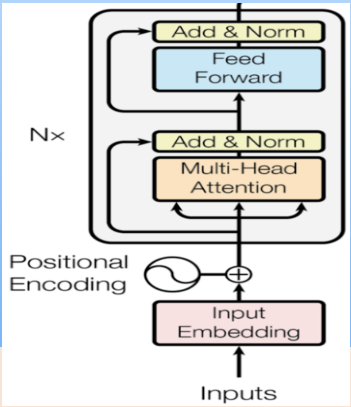

## 16쪽 · Transformer: 학습 및 텍스트 생성

In [ ]:
transformer_model = TransformerLanguageModel(
    vocab_size=vocab_size,
    embedding_dim=64,
    num_heads=4,
    ff_dim=128
).to(device)

train_model(
    transformer_model,
    loader,
    epochs=250
)

prompts = [
    "i want",
    "find a",
    "show me",
    "can you",
    "where can"
]

for prompt in prompts:
    print(
        prompt,
        "→",
        generate_text(
            transformer_model,
            prompt=prompt
        )
    )

## 17쪽 · TransformerLanguageModel: Padding Mask가 있는 Causal Self-Attention

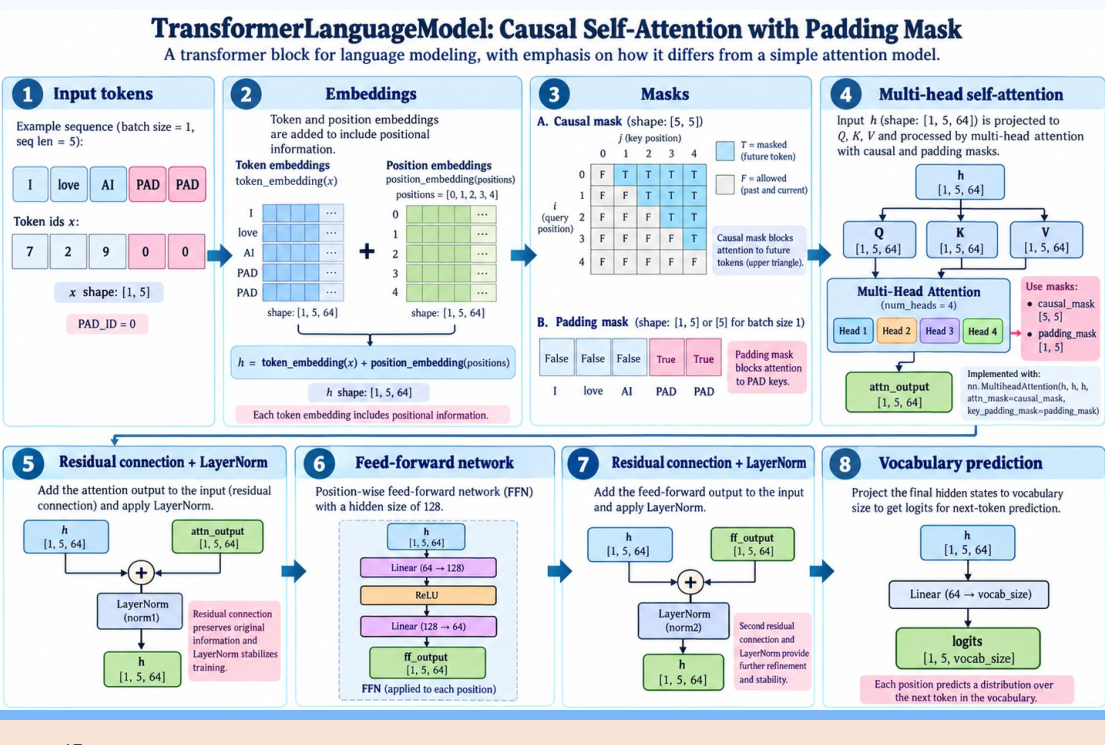

## 18쪽 · 네 가지 모델 모두 비교: 텍스트 생성

- 이 작은 corpus에서 어느 모델이 "가장 좋은" 문장을 생성하는지는 강조하지 않는다.
- 목적은 동일한 예측 작업이 점차 서로 다른 메커니즘을 이용해 어떻게 구현되는지를 이해하는 것이다.

In [ ]:
models = {
    "RNN": rnn_model,
    "LSTM": lstm_model,
    "Attention": attention_model,
    "Transformer": transformer_model
}

for name, model in models.items():
    print(
        f"{name:12}:",
        generate_text(
            model,
            prompt="i want"
        )
    )

## 19쪽 · 네 가지 모델 모두 비교: 파라미터 수

- 이는 개선된 architecture에 추가 비용이 없지는 않다는 것을 보여 준다.

**코드 설명**

- `p.numel()`: 각 파라미터 Tensor의 원소 개수를 반환한다. 예를 들어 Shape이 `(64, 128)`인 weight Tensor에는 `64 × 128 = 8,192`개의 원소가 있다.
- `p.requires_grad`: 학습 중 일부 파라미터는 고정될 수 있다(`requires_grad=False`). 이 조건은 backpropagation 동안 실제로 업데이트되는 파라미터만 계산하도록 한다.
- `model.parameters()`: 모델의 모든 파라미터 Tensor(weight와 bias)를 반환한다.

In [ ]:
def count_parameters(model):
    return sum(
        # 각 파라미터 Tensor의 원소 개수를 반환한다.
        # 예: (64, 128) -> 64*128 = 8192개 원소
        p.numel()
        # 모델의 모든 파라미터 Tensor(weight, bias)를 가져온다.
        for p in model.parameters()
        # 실제 backpropagation에서 갱신되는 파라미터만 계산한다.
        if p.requires_grad
    )

for name, model in models.items():
    print(
        f"{name:12}",
        f"{count_parameters(model):,}"
    )

**원본 실행 결과**

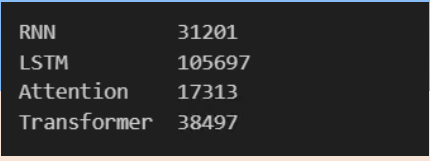

## 20쪽 · Loss 기록 및 그래프

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.plot(rnn_losses, label="RNN")
plt.plot(lstm_losses, label="LSTM")
plt.plot(attention_losses, label="Attention")
plt.plot(transformer_losses, label="Transformet")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Language Model Training")
plt.legend()
plt.grid()
plt.show()

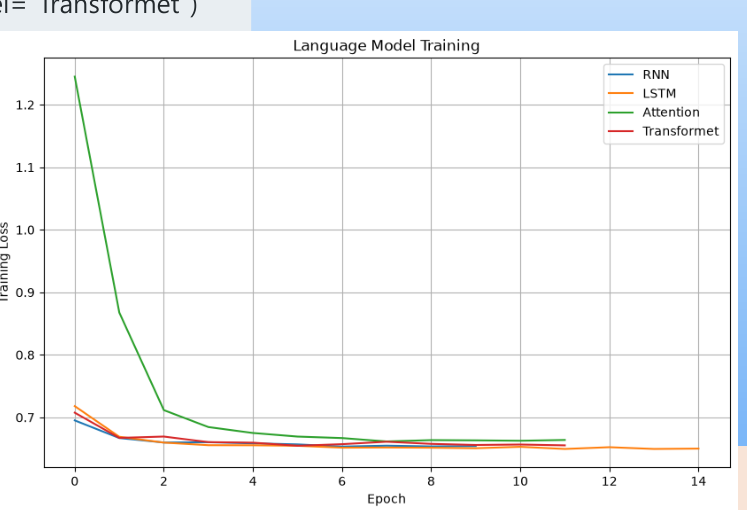

## 21쪽 · 실제 데이터

- BeRP (Berkeley Restaurant Project) 다운로드: [https://github.com/wooters/berp-trans?utm_source=chatgpt.com](https://github.com/wooters/berp-trans?utm_source=chatgpt.com) — `transcript.txt`만 다운로드한다.
- Corpus를 교체한다.

In [ ]:
def load_berp_sentences(filename="transcript.txt"):
    sentences = []
    with open(filename, "r", encoding="utf-8") as file:
        for line in file:
            parts = line.strip().split(maxsplit=1)
            if len(parts) != 2:
                continue
            sentence = parts[1].lower()
            sentences.append(sentence)
    return sentences

sentences = load_berp_sentences("transcript.txt")
print("Number of sentences", len(sentences))

for sentence in sentences[:10]:
    print(sentence)

## 22쪽 · 실제 데이터

- **파일 내부**

```text
1 I Want to Eat Pizza
2 Where Is the Restaurant
3 Hello How Are You
4
5 I Like Hamburgers
```

- `split(maxsplit=1)`은 첫 번째 공백을 기준으로 문자열을 분할하여 최대 두 개의 요소를 생성한다.

```python
['1', 'I Want to Eat Pizza']
```

- `if len(parts) != 2: continue`: 유효하지 않은 줄을 무시한다.

```python
parts = ['4']
```

- `sentence = parts[1].lower()`:

```python
parts = ['1', 'I Want to Eat Pizza']
# →
sentence = "i want to eat pizza"
```

## 23쪽 · 실제 데이터

- 총 8,566개 문장 중 2,000개만 사용한다.

In [ ]:
import random

random.seed(44)
random.shuffle(sentences)
sentences = sentences[:2000]

- Vocabulary 코드는 그대로 유지한다(현재 약 1,080개 단어).
- `MAX_LEN = 20`으로 늘린다(또는 23, 24, …).
- `LanguageModelDataset`은 변경하지 않는다.
- Batch size를 `64`로 늘린다(VRAM이 허용하면 `32`, `128`도 가능).
- Epoch 수를 `30`으로 줄인다(또는 loss curve를 확인하면서 `250` 사용).
- Language model, 학습, `generate_text` 등은 그대로 유지한다.